# SQL Agent Workflow —— chinook.db

参考 `sql-agent.ipynb`，把下面 7 个阶段串成一条**确定性流水线**：

> 数据库解析 → Table 选择 → SQL 生成 → SQL 校验 → SQL 改写 → SQL 执行 → 结果汇总

设计原则：每个阶段各一次独立 LLM 调用，**编排与回环逻辑全部写在 Python 层**——
可单步调试、可断言、可复现；失败时诚实返回原因，绝不编造数据。

## 与参考实现（`sql-agent.ipynb`）的角色对照

参考 notebook 里散落着若干「角色 / 分工」，本实现把它们全部收拢为函数或类。
唯一没有照搬**形态**的是 `@function_tool parse_table`——它本质是「让选表 Agent 按需调
工具查表字段」，本实现改为**在选表后一次性把 schema 灌进提示词**：功效等价、更确定、无需多一轮工具往返。

| 参考中的角色 / 工具 | 本实现的等价模块 |
|---|---|
| `@function_tool parse_table`（按需取表字段） | `table_catalog()` / `schema_context()` |
| `SQLTableSelectAgent`（"SQL Planer" 选表） | `select_tables()` |
| `SQLGeneratorAgent`（参考里是空壳） | `generate_sql()` |
| 「执行 sql」 | `is_readonly()` + `check_sql()` + `execute_sql()` |
| 「sql rewrite」 | `rewrite_sql()` |
| `SQLResultSummaryAgent`（参考里是空壳） | `summarize()` |
| `ask_gpt()` | `chat()` |
| 造题 prompts（question / answer） | `build_eval_set()` |
| 末尾 5 步 pipeline 注释 | `run_workflow()` |
| ——（本实现新增） | `is_readonly()` 只读守卫、`ChatBI` 多轮对话、`render_result()` 自动图表 |

## 0. 环境准备（脱敏加载 .env）

In [1]:
"""环境准备：逐级向上找 .env → 伪装成 OpenAI 兼容接口 → 定位数据库。

不变量：源码中不出现任何明文 Key、不出现本机绝对路径。
"""
import os
import re
import json
from pathlib import Path

from dotenv import load_dotenv


def find_up(filename: str):
    """从当前工作目录逐级向上查找文件，返回第一个命中的绝对路径。"""
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / filename).exists():
            return p / filename
    return None


# 1) 找 .env（通常在项目根目录）
_env_path = find_up(".env")
if _env_path is None:
    raise RuntimeError("没找到 .env：请从本 notebook 所在目录逐级向上放置 .env")
load_dotenv(_env_path, override=True)

# 2) 把 DeepSeek 的 Key 伪装成 OpenAI 兼容接口
os.environ["OPENAI_API_KEY"] = os.environ["DEEPSEEK_API_KEY"]
os.environ["OPENAI_BASE_URL"] = os.environ.get("DEEPSEEK_BASE_URL", "https://api.deepseek.com/v1")
MODEL = os.environ.get("DEEPSEEK_MODEL", "deepseek-chat")

# 3) 定位数据库文件
_db_path = find_up("chinook.db")
if _db_path is None:
    raise RuntimeError("没找到 chinook.db：请把数据库放在本 notebook 同目录")
DB_URL = f"sqlite:///{_db_path}"


def _redact(p: Path) -> str:
    """把家目录替换成 ~，避免把本机用户名写进 notebook 输出。"""
    s = str(p)
    home = str(Path.home())
    return s.replace(home, "~") if s.startswith(home) else s


print("已加载 .env :", _redact(_env_path))
print("数据库文件  :", _redact(_db_path))
print("模型        :", MODEL)

已加载 .env : ~/Downloads/padow-ai/.env
数据库文件  : ~/Downloads/padow-ai/Week11/Week11/04_SQL-Code-Agent-Demo/chinook.db
模型        : deepseek-v4-flash


## 1. 数据库解析（DBParser）

把「表 / 字段统计 / 外键 / 样例」变成 LLM 可读的结构化上下文。
字段统计包含：类型、是否可空、主键、distinct 数、缺失数、最大/最小、众数、随机样例。

In [2]:
"""数据库解析：产出 schema、外键关系与样例，供后续阶段喂给 LLM。"""
import traceback

import pandas as pd
from sqlalchemy import create_engine, inspect, func, select, Table, MetaData, text


class DBParser:
    """解析 sqlite / mysql 数据库的元数据与样例。"""

    def __init__(self, db_url: str) -> None:
        self.db_url = db_url
        self.db_type = "mysql" if "mysql" in db_url else "sqlite"

        self.engine = create_engine(db_url, echo=False)
        self.inspector = inspect(self.engine)
        self.table_names = self.inspector.get_table_names()

        self._table_fields = {}   # 每张表的字段元数据
        self.foreign_keys = []    # 全库外键
        self._table_sample = {}   # 每张表的第一行样例

        with self.engine.connect() as conn:
            for table_name in self.table_names:
                print("Table ->", table_name)
                self._table_fields[table_name] = {}

                # 累计外键
                self.foreign_keys += [
                    {
                        "constrained_table": table_name,
                        "constrained_columns": x["constrained_columns"],
                        "referred_table": x["referred_table"],
                        "referred_columns": x["referred_columns"],
                    }
                    for x in self.inspector.get_foreign_keys(table_name)
                ]

                table_instance = Table(table_name, MetaData(), autoload_with=self.engine)
                table_columns = self.inspector.get_columns(table_name)
                self._table_fields[table_name] = {x["name"]: dict(x) for x in table_columns}

                # 逐字段做统计
                for column_meta in table_columns:
                    col = getattr(table_instance.columns, column_meta["name"])
                    meta = self._table_fields[table_name][column_meta["name"]]

                    # distinct 数
                    meta["distinct"] = conn.execute(
                        select(func.count(func.distinct(col)))
                    ).fetchone()[0]

                    # 文本字段取众数（出现次数最多的值）
                    field_type = str(meta["type"]).lower()
                    if "text" in field_type or "char" in field_type:
                        row = conn.execute(
                            select(col, func.count().label("count"))
                            .group_by(col).order_by(func.count().desc()).limit(1)
                        ).fetchone()
                        meta["mode"] = row[0] if row else None

                    # 缺失数 / 最大 / 最小
                    meta["nan_count"] = conn.execute(
                        select(func.count()).filter(col == None)  # noqa: E711
                    ).fetchone()[0]
                    meta["max"] = conn.execute(select(func.max(col))).fetchone()[0]
                    meta["min"] = conn.execute(select(func.min(col))).fetchone()[0]

                    # 随机样例
                    random_value = [
                        str(r[0]) for r in conn.execute(select(col).limit(10)).all()
                        if r[0] is not None
                    ]
                    meta["random"] = list(set(random_value))[:3]

                # 表样例（第一行）
                sample = conn.execute(select(table_instance).limit(1)).fetchone()
                df = pd.DataFrame([sample]) if sample is not None else pd.DataFrame()
                df.columns = [x["name"] for x in table_columns]
                self._table_sample[table_name] = df

    # ---------- 对外接口 ----------
    def get_table_fields(self, table_name) -> pd.DataFrame:
        """获取表字段信息。"""
        return pd.DataFrame.from_dict(self._table_fields[table_name]).T

    def get_data_relations(self) -> pd.DataFrame:
        """获取数据库连接信息（主键与外键）。"""
        return pd.DataFrame(self.foreign_keys)

    def get_table_sample(self, table_name) -> pd.DataFrame:
        """获取表样例（第一行）。"""
        return self._table_sample[table_name]

    def check_sql(self, sql: str):
        """试跑 SQL，返回 (是否可执行, 报错信息)。"""
        try:
            with self.engine.begin() as conn:  # begin() 自动提交并关闭
                conn.execute(text(sql))
            return True, "ok"
        except Exception:
            return False, traceback.format_exc(limit=1)

    def execute_sql(self, sql: str):
        """只读执行，返回 (列名, 全部结果行)。"""
        with self.engine.begin() as conn:
            result = conn.execute(text(sql))
            columns = list(result.keys())
            rows = [tuple(r) for r in result.fetchall()]
            return columns, rows

### 建立解析器，看一眼外键与样例

In [3]:
parser = DBParser(DB_URL)

parser.get_data_relations()

Table -> albums
Table -> artists
Table -> customers
Table -> employees
Table -> genres
Table -> invoice_items
Table -> invoices
Table -> media_types
Table -> playlist_track
Table -> playlists
Table -> tracks


,constrained_table,constrained_columns,referred_table,referred_columns
0,albums,[ArtistId],artists,[ArtistId]
1,customers,[SupportRepId],employees,[EmployeeId]
2,employees,[ReportsTo],employees,[EmployeeId]
3,invoice_items,[TrackId],tracks,[TrackId]
4,invoice_items,[InvoiceId],invoices,[InvoiceId]
5,invoices,[CustomerId],customers,[CustomerId]
6,playlist_track,[TrackId],tracks,[TrackId]
7,playlist_track,[PlaylistId],playlists,[PlaylistId]
8,tracks,[MediaTypeId],media_types,[MediaTypeId]
9,tracks,[GenreId],genres,[GenreId]


In [4]:
parser.get_table_sample("artists")

,ArtistId,Name
0,1,AC/DC


## 2. 只读安全守卫

LLM 生成的 SQL 不可信。这里用**结构性护栏**（而非提示词约定）先拦一道：
只允许单条 `SELECT` / `WITH`，拒绝写入类与 DDL 关键字、拒绝多语句。

先剔除注释与字符串字面量再扫描关键字，避免把数据里的词误判成语句
（例如某个歌名里出现 "update"）。

In [5]:
_FORBIDDEN = re.compile(
    r"\b(insert|update|delete|drop|alter|create|replace|truncate|"
    r"attach|detach|pragma|vacuum|reindex|grant|revoke)\b",
    re.IGNORECASE,
)


def is_readonly(sql: str):
    """只允许单条 SELECT / WITH 只读查询，返回 (是否通过, 原因)。"""
    if not sql or not sql.strip():
        return False, "空 SQL"

    s = re.sub(r"--[^\n]*", "", sql)                 # 去行注释
    s = re.sub(r"/\*.*?\*/", "", s, flags=re.S)      # 去块注释
    s = s.strip().rstrip(";").strip()

    if ";" in s:
        return False, "不允许多条语句"
    if not re.match(r"^(select|with)\b", s, re.IGNORECASE):
        return False, "只允许 SELECT / WITH 只读查询"

    # 剔除字符串字面量后再扫描关键字
    scan = re.sub(r"'(?:[^']|'')*'", "''", s)
    scan = re.sub(r'"(?:[^"]|"")*"', '""', scan)
    m = _FORBIDDEN.search(scan)
    if m:
        return False, f"检测到非只读关键字：{m.group(0)}"
    return True, "ok"


# 自测
for _sql in ["SELECT COUNT(*) FROM albums;", "WITH t AS (SELECT 1) SELECT * FROM t",
             "DROP TABLE albums;", "SELECT 1; SELECT 2;"]:
    print(is_readonly(_sql), "<-", _sql)

(True, 'ok') <- SELECT COUNT(*) FROM albums;
(True, 'ok') <- WITH t AS (SELECT 1) SELECT * FROM t
(False, '只允许 SELECT / WITH 只读查询') <- DROP TABLE albums;
(False, '不允许多条语句') <- SELECT 1; SELECT 2;


## 3. LLM 封装（DeepSeek · Chat Completions）

In [6]:
"""统一的 LLM 调用入口：带简单重试，可选 JSON 模式。"""
from openai import OpenAI

client = OpenAI(api_key=os.environ["OPENAI_API_KEY"], base_url=os.environ["OPENAI_BASE_URL"])


def chat(system: str, user: str, json_mode: bool = False, temperature: float = 0.0) -> str:
    """一次同步 Chat Completions 调用。"""
    kwargs = dict(
        model=MODEL,
        temperature=temperature,
        messages=[
            {"role": "system", "content": system},
            {"role": "user", "content": user},
        ],
    )
    if json_mode:
        kwargs["response_format"] = {"type": "json_object"}

    last_err = None
    for _ in range(3):
        try:
            resp = client.chat.completions.create(**kwargs)
            return (resp.choices[0].message.content or "").strip()
        except Exception as e:  # noqa: BLE001
            last_err = e
    raise RuntimeError(f"LLM 调用失败：{last_err}")


def strip_code_fence(text: str) -> str:
    """去掉 ```sql ... ``` 之类的围栏，只留正文。"""
    text = text.strip()
    text = re.sub(r"^```[a-zA-Z]*\s*", "", text)
    text = re.sub(r"\s*```$", "", text)
    return text.strip()

## 4. 流水线各阶段函数

In [7]:
"""Stage 2 / 3 / 5 / 7 的具体实现。"""


def table_catalog(parser: DBParser) -> str:
    """给 LLM 的「表清单 + 字段」。"""
    lines = []
    for t in parser.table_names:
        cols = list(parser.get_table_fields(t).index)
        lines.append(f"- {t}（字段：{', '.join(cols)}）")
    return "\n".join(lines)


def select_tables(question: str, parser: DBParser) -> list: ## == SQLTableSelectAgent` （SQL Planer）
    """Stage 2：结合用户提问，选出回答问题所需的最小表集合。"""
    system = "你是一个专业的 SQL 专家。请从候选表里选出回答该问题所需的最小表集合。"
    rels = parser.get_data_relations()
    rels_text = rels.to_string(index=False) if len(rels) else "无"
    user = (
        f"用户问题：{question}\n\n"
        f"候选表：\n{table_catalog(parser)}\n\n"
        f"表间外键关系：\n{rels_text}\n\n"
        '只输出 JSON：{"tables": ["表名", ...]}'
    )
    raw = strip_code_fence(chat(system, user, json_mode=True))
    try:
        picked = json.loads(raw).get("tables", [])
    except json.JSONDecodeError:
        picked = re.findall(r"[a-zA-Z_][a-zA-Z0-9_]*", raw)
    picked = [t for t in picked if t in parser.table_names]
    return picked or parser.table_names[:1]


def schema_context(tables: list, parser: DBParser) -> str:
    """把选中表的字段、样例与外键拼成上下文。"""
    parts = []
    for t in tables:
        parts.append(
            f"### 表 {t}\n字段：\n{parser.get_table_fields(t).to_markdown()}\n"
            f"样例：\n{parser.get_table_sample(t).to_markdown(index=False)}"
        )
    rels = parser.get_data_relations()
    if len(rels):
        rels = rels[rels["constrained_table"].isin(tables) & rels["referred_table"].isin(tables)]
        if len(rels):
            parts.append(f"### 选中表之间的外键\n{rels.to_string(index=False)}")
    return "\n\n".join(parts)


def generate_sql(question: str, tables: list, parser: DBParser) -> str:
    """Stage 3：结合提问与选中表生成 SQL。"""
    system = "你是一个专业的 SQLite 专家。只生成一条只读 SELECT 语句，不要解释，不要写多语句。"
    user = (
        f"用户问题：{question}\n\n"
        f"相关表信息：\n{schema_context(tables, parser)}\n\n"
        "请只输出 SQL（可带分号）："
    )
    return strip_code_fence(chat(system, user))


def rewrite_sql(question: str, sql: str, error: str, tables: list, parser: DBParser) -> str:
    """Stage 5：把「报错 + 原 SQL + 问题 + schema」回灌 LLM 修正。"""
    system = "你是一个专业的 SQLite 专家。上一次的 SQL 执行失败，请根据报错修正。只输出修正后的单条只读 SELECT。"
    user = (
        f"用户问题：{question}\n\n"
        f"相关表信息：\n{schema_context(tables, parser)}\n\n"
        f"上一次 SQL：\n{sql}\n\n"
        f"报错信息：\n{error}\n\n"
        "请输出修正后的 SQL："
    )
    return strip_code_fence(chat(system, user))


def summarize(question: str, sql: str, rows: list, max_rows: int = 50) -> str:
    """Stage 7：把「问题 + SQL + 结果」组织为自然语言结论。"""
    system = "你是一个数据分析助手。请依据 SQL 执行结果，用简洁自然语言回答问题，不要编造数据。"
    user = (
        f"用户问题：{question}\n\n"
        f"执行的 SQL：\n{sql}\n\n"
        f"执行结果（共 {len(rows)} 行，最多展示 {max_rows} 行）：\n{rows[:max_rows]}\n\n"
        "请给出自然语言结论："
    )
    return chat(system, user)

## 5. 编排：7 阶段串接 + 校验/改写闭环

`run_workflow()` 是唯一的编排入口：按顺序调用各阶段，遇到校验失败就把控制权交给
`rewrite_sql()`，最多重试 `MAX_REWRITE` 次；仍失败则返回失败轨迹，**不编造结果**。

In [8]:
MAX_REWRITE = 3


def run_workflow(question: str, parser: DBParser, verbose: bool = True) -> dict:
    """执行完整 SQL Agent 工作流，返回带轨迹的结果字典。"""
    trace = {
        "question": question, "tables": None, "sql": None,
        "attempts": 0, "ok": False, "error": None, "columns": None, "rows": None, "answer": None,
    }

    def log(msg):
        if verbose:
            print(msg)

    # Stage 2：Table 选择
    tables = select_tables(question, parser)
    trace["tables"] = tables
    log(f"[2] 选中表：{tables}")

    # Stage 3：SQL 生成
    sql = generate_sql(question, tables, parser)
    log(f"[3] 生成 SQL：{sql}")

    # Stage 4 / 5：校验 → 改写 闭环
    ok, err = False, None
    for attempt in range(MAX_REWRITE + 1):
        ro_ok, ro_msg = is_readonly(sql)
        if not ro_ok:
            ok, err = False, ro_msg
        else:
            ok, err = parser.check_sql(sql)
        trace["attempts"] = attempt + 1
        detail = "通过" if ok else "失败 → " + str(err).strip().splitlines()[-1]
        log(f"[4] 校验（第 {attempt + 1} 次）：{detail}")
        if ok or attempt == MAX_REWRITE:
            break
        sql = rewrite_sql(question, sql, str(err), tables, parser)
        log(f"[5] 改写 SQL：{sql}")

    trace["sql"] = sql
    trace["ok"] = ok
    trace["error"] = None if ok else err
    if not ok:
        trace["answer"] = "抱歉，未能生成可执行的 SQL，已放弃（不编造结果）。"
        return trace

    # Stage 6：SQL 执行
    columns, rows = parser.execute_sql(sql)
    trace["columns"] = columns
    trace["rows"] = rows
    log(f"[6] 执行结果：{len(rows)} 行")

    # Stage 7：结果汇总
    answer = summarize(question, sql, rows)
    trace["answer"] = answer
    log(f"[7] 汇总回答：{answer}")
    return trace

## 6. Demo：跑几个示例问题

In [33]:
import sqlite3, pandas as pd
con = sqlite3.connect('chinook.db')
# cur = con.cursor()
sql1 = (
    "SELECT g.Name, SUM(ii.Quantity) AS total_sold "
    "FROM genres g JOIN tracks t ON t.GenreId = g.GenreId "
    "JOIN invoice_items ii ON ii.TrackId = t.TrackId "
    "GROUP BY g.GenreId, g.Name ORDER BY total_sold DESC LIMIT 5"
)

sql2 = (
    "SELECT BillingCountry, COUNT(*) AS ArtistCount "
    "FROM invoices GROUP BY BillingCountry "
    "ORDER BY ArtistCount DESC LIMIT 5"
)

sql_test1 = pd.read_sql(sql1, con)
sql_test2 = pd.read_sql(sql2, con)

print(sql_test1)
print(sql_test2)


                 Name  total_sold
0                Rock         835
1               Latin         386
2               Metal         264
3  Alternative & Punk         244
4                Jazz          80
  BillingCountry  ArtistCount
0            USA           91
1         Canada           56
2         France           35
3         Brazil           35
4        Germany           28


In [9]:
DEMO_QUESTIONS = [
    "数据库里一共有多少首歌曲（tracks）？",
    "销量最高的 5 个流派分别是什么，各卖了多少？",
    "哪个客户的累计消费金额最高？",
    "每位客服（SupportRep）各自负责多少位客户？",
    "2010 年的总销售额是多少？",
]

for q in DEMO_QUESTIONS:
    print("=" * 72)
    print("Q:", q)
    res = run_workflow(q, parser)
    print("A:", res["answer"])

Q: 数据库里一共有多少首歌曲（tracks）？


[2] 选中表：['tracks']


[3] 生成 SQL：SELECT COUNT(*) FROM tracks;
[4] 校验（第 1 次）：通过
[6] 执行结果：1 行


[7] 汇总回答：数据库里一共有 **3503 首歌曲（tracks）**。
A: 数据库里一共有 **3503 首歌曲（tracks）**。
Q: 销量最高的 5 个流派分别是什么，各卖了多少？


[2] 选中表：['genres', 'tracks', 'invoice_items']


[3] 生成 SQL：SELECT g.Name, SUM(ii.Quantity) AS total_sold
FROM genres g
JOIN tracks t ON t.GenreId = g.GenreId
JOIN invoice_items ii ON ii.TrackId = t.TrackId
GROUP BY g.GenreId, g.Name
ORDER BY total_sold DESC
LIMIT 5;
[4] 校验（第 1 次）：通过
[6] 执行结果：5 行


... (6 outputs left out)

[7] 汇总回答：共有 3 位客服有负责客户：

- Jane Peacock（EmployeeId 3）：21 位客户
- Margaret Park（EmployeeId 4）：20 位客户
- Steve Johnson（EmployeeId 5）：18 位客户

三人合计负责 59 位客户。
A: 共有 3 位客服有负责客户：

- Jane Peacock（EmployeeId 3）：21 位客户
- Margaret Park（EmployeeId 4）：20 位客户
- Steve Johnson（EmployeeId 5）：18 位客户

三人合计负责 59 位客户。
Q: 2010 年的总销售额是多少？


[2] 选中表：['invoices']


[3] 生成 SQL：SELECT SUM(Total) FROM invoices WHERE InvoiceDate >= '2010-01-01' AND InvoiceDate < '2011-01-01';
[4] 校验（第 1 次）：通过
[6] 执行结果：1 行


[7] 汇总回答：2010 年的总销售额为 **481.45**。
A: 2010 年的总销售额为 **481.45**。


In [10]:
# 手动问答入口：把 INTERACTIVE 改为 True 即可在本地交互（nbconvert 无头执行时会跳过）
INTERACTIVE = False
if INTERACTIVE:
    while True:
        q = input("请输入问题（直接回车退出）：").strip()
        if not q:
            break
        res = run_workflow(q, parser)
        print("A:", res["answer"])

## 7. 问题模拟生成器（QuestionSimulator）

参考 notebook 的「模拟生成问题」就是一个**问题模拟生成器**：用 LLM 对着表结构造题。
本 notebook 此前只有 `build_eval_set()`，它是这个生成器的**特化版**（只造单值统计题、绑定评测用途）。
这里把它抽成可复用模块：

- `simulate_question()`：对单表造 1 题，并给出参考 SQL 与真值；
- `simulate_questions()`：批量造题，可按题型（`count` / `group`）与是否「用户口吻」控制；
- `simulate_out_of_scope()`：造**越界负样本**（与库无关的问题），用于测试第 9 节的范围守门人。

> 造题与判分用同类模型，存在自证偏差；它只用于构造测试 / 演示数据，不代表真实用户分布。

In [11]:
"""问题模拟生成器：从数据库内容合成用户提问（含参考 SQL 与真值）。"""

EVAL_TABLES = ["albums", "tracks", "invoices", "customers", "employees"]

_STYLES = {
    "count": "答案是单个数字的计数 / 统计类问题",
    "group": "答案是一组类别及对应数值的分组对比类问题",
}

_GEN_PROMPT = """你是一个数据库专家。请针对下面这张表，提出一个{style_desc}的自然语言问题。
只输出问题本身，不要有任何多余内容。

表名称：{table}
字段：{fields}
表样例：
{sample}
表结构：
{schema}
"""

_SQL_PROMPT = """你是一个 SQLite 专家。请针对以下问题和表，生成一条只读 SELECT。只输出 SQL，不要解释。

表名称：{table}
字段：{fields}
表样例：
{sample}
表结构：
{schema}
问题：{question}
"""

_REWRITE_PROMPT = """请把下面这个偏技术的提问，改写成普通用户会问的口吻，不要出现表名 / 字段名等术语。
只输出改写后的提问。

原始问题：{question}
涉及的表：{table}
"""


def simulate_question(parser: DBParser, table: str, style: str = "count", user_style: bool = False) -> dict:
    """对单张表合成 1 个问题，并给出参考 SQL 与真值（真值可能为 None）。"""
    schema = parser.get_table_fields(table).to_markdown()
    sample = parser.get_table_sample(table).to_markdown(index=False)
    fields = ", ".join(parser.get_table_fields(table).index)

    question = strip_code_fence(chat("你是数据库专家。", _GEN_PROMPT.format(
        table=table, fields=fields, sample=sample, schema=schema,
        style_desc=_STYLES.get(style, _STYLES["count"]))))
    if user_style:
        question = strip_code_fence(chat("你是提问改写助手。", _REWRITE_PROMPT.format(
            question=question, table=table)))

    sql = strip_code_fence(chat("你是 SQLite 专家。", _SQL_PROMPT.format(
        table=table, fields=fields, sample=sample, schema=schema, question=question)))

    ref_value = None
    if (is_readonly(sql)[0]
            and not re.search(r"\b(group\s+by|having)\b", sql, re.IGNORECASE)
            and parser.check_sql(sql)[0]):
        _, rows = parser.execute_sql(sql)
        if len(rows) == 1 and len(rows[0]) == 1:
            ref_value = rows[0][0]

    return {"table": table, "style": style, "question": question,
            "ref_sql": sql, "ref_value": ref_value}


def simulate_questions(parser: DBParser, tables=None, n_per_table: int = 1,
                       style: str = "count", user_style: bool = False, max_try: int = 4) -> list:
    """批量合成问题；只保留「可执行且答案为单值」的题（便于自动判分）。"""
    tables = tables or parser.table_names
    items = []
    for t in tables:
        got = 0
        for _ in range(max_try):
            if got >= n_per_table:
                break
            try:
                rec = simulate_question(parser, t, style=style, user_style=user_style)
            except Exception:  # noqa: BLE001
                continue
            if rec["ref_value"] is None:
                continue
            got += 1
            items.append(rec)
    return items


def simulate_out_of_scope(n: int = 3) -> list:
    """负样本：与 chinook 音乐商店数据库完全无关的问题，用于测试范围判定。"""
    prompt = (f"请生成 {n} 个与「音乐商店销售数据库」完全无关的自然语言问题"
              '（如天气、闲聊、别的领域）。只输出 JSON：{"questions": ["...", "..."]}')
    raw = strip_code_fence(chat("你是测试数据生成器。", prompt, json_mode=True))
    try:
        qs = json.loads(raw).get("questions", [])
    except json.JSONDecodeError:
        qs = [ln.strip("- 0123456789.").strip() for ln in raw.splitlines() if ln.strip()]
    return [q for q in qs if q][:n]

In [12]:
print("=== 正向：对若干表模拟生成提问（并改写为用户口吻）===")
sim = simulate_questions(parser, tables=EVAL_TABLES, n_per_table=1, style="count", user_style=True)
for s in sim:
    print(f"- [{s['table']}] {s['question']}  => 真值 {s['ref_value']}")

print("\n=== 负向：越界问题（用于测试范围守门人）===")
oos = simulate_out_of_scope(4)
for q in oos:
    print("-", q)

=== 正向：对若干表模拟生成提问（并改写为用户口吻）===


- [albums] 总共有多少张专辑？  => 真值 347
- [tracks] 有多少首歌曲属于编号为 1 的音乐类型？  => 真值 1297
- [invoices] 总共有多少张发票？  => 真值 412
- [customers] 一共有多少位客户？  => 真值 59
- [employees] 现在一共有多少名员工？  => 真值 8

=== 负向：越界问题（用于测试范围守门人）===


- 今天北京的最高气温是多少？
- 番茄炒蛋一般需要准备哪些食材？
- 太阳系中距离太阳最远的行星是哪一颗？
- 去杭州西湖游玩一天，推荐哪些景点？


## 8. 小型评测

复用第 7 节的模拟生成器造一批**单值统计题**（`build_eval_set()` 是它的薄封装），
再把每题喂给 `run_workflow()`，比较最终结果的数值与参考值是否一致。

> 造题与答题用同类模型，存在自证偏差；指标只用于判断流程是否走得通。

In [13]:
from tqdm.auto import tqdm


def build_eval_set(parser: DBParser, tables=None):
    """评测集 = 单表单值统计题（第 7 节模拟生成器的特化调用）。"""
    return simulate_questions(parser, tables=tables or EVAL_TABLES, n_per_table=1, style="count")


eval_set = build_eval_set(parser)
print(f"评测集共 {len(eval_set)} 题")
for it in eval_set:
    print(f"- [{it['table']}] {it['question']} => {it['ref_value']}")

评测集共 5 题
- [albums] albums 表中共有多少张专辑？ => 347
- [tracks] 有多少首歌曲的 UnitPrice 为 0.99？ => 3290
- [invoices] invoices 表中共有多少张发票记录？ => 412
- [customers] customers 表中共有多少位客户？ => 59
- [employees] 员工表中共有多少名员工？ => 8


In [14]:
def values_match(a, b, tol: float = 1e-6) -> bool:
    """数值容差比较，非数值退化为字符串比较。"""
    try:
        return abs(float(a) - float(b)) <= tol
    except (TypeError, ValueError):
        return str(a).strip() == str(b).strip()


records = []
for it in tqdm(eval_set):
    res = run_workflow(it["question"], parser, verbose=False)
    pred = None
    match = False
    if res["ok"] and res["rows"] and len(res["rows"]) == 1 and len(res["rows"][0]) == 1:
        pred = res["rows"][0][0]
        match = values_match(pred, it["ref_value"])
    records.append({
        "question": it["question"],
        "ref_value": it["ref_value"],
        "pred_value": pred,
        "exec_ok": res["ok"],
        "match": match,
        "rewrites": res["attempts"] - 1,
    })

eval_df = pd.DataFrame(records)
eval_df

  0%|          | 0/5 [00:00<?, ?it/s]

,question,ref_value,pred_value,exec_ok,match,rewrites
0,albums 表中共有多少张专辑？,347,347,True,True,0
1,有多少首歌曲的 UnitPrice 为 0.99？,3290,3290,True,True,0
2,invoices 表中共有多少张发票记录？,412,412,True,True,0
3,customers 表中共有多少位客户？,59,59,True,True,0
4,员工表中共有多少名员工？,8,8,True,True,0


### 汇总指标

In [15]:
print(f"题量            : {len(eval_df)}")
print(f"执行成功率      : {eval_df['exec_ok'].mean():.2%}")
print(f"结果匹配率      : {eval_df['match'].mean():.2%}")
print(f"平均改写次数    : {eval_df['rewrites'].mean():.2f}")

题量            : 5
执行成功率      : 100.00%
结果匹配率      : 100.00%
平均改写次数    : 0.00


## 9. 范围判定与用户对接（ChatBI）

真·对接用户，光有「链路」不够，还差三道闸门——且闸门必须加在**生成 SQL 之前**，
否则越界问题会被硬编成一条 SQL：

```
用户输入
  → [A] 追问改写  rewrite_followup()   有历史时把追问改写成自包含问题
  → [B] 范围判定  scope_check()        in / out / ambiguous + 理由
  → [C] 分支
        out       → 直接谢绝，并提示可以问什么（不生成任何 SQL）
        ambiguous → 反问澄清（不生成任何 SQL）
        in        → 交给 7 阶段流水线 → 表格 / 图表 / 分析
```

- **范围判定是结构性闸门**：守门人只输出 JSON，并做**结构兜底**——若它声称 `in` 却落不到
  任何真实表，就强制降级为 `ambiguous`，避免硬编 SQL。
- `ChatBI.ask()` 维护会话历史（最近 5 轮），把三步串起来。
- `render_result()`：结果出表格；「1 类别列 + 1 数值列」时**自动出柱状图**。

In [16]:
"""范围判定 + 多轮 ChatBI + 结果渲染。"""
import warnings
import matplotlib.pyplot as plt
from IPython.display import display

# 中文字体：避免图表中文缺字 —— 缺字警告会把本机绝对路径写进 notebook 输出
plt.rcParams["font.sans-serif"] = ["Arial Unicode MS", "Heiti SC", "Hiragino Sans GB", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

_SCOPE_SYSTEM = (
    "你是数据库助手的守门人。用户只能询问 chinook 音乐商店数据库里的数据。"
    "请判断用户问题是否可答，并只输出 JSON。"
)
_SCOPE_USER = """数据库包含以下表与字段：
{catalog}

用户问题：{question}

请只输出 JSON：
{{"scope": "in" | "out" | "ambiguous",
  "reason": "简短理由",
  "tables": ["若为 in，给出可能用到的表名"],
  "clarify": "若为 ambiguous，给出向用户的反问；否则空字符串"}}

判定标准：
- in：用上面的表 / 字段能查出来。
- out：与这个数据库无关（闲聊、别的领域、需要库外数据）。
- ambiguous：意图不完整或有歧义，需要向用户澄清。"""


def scope_check(question: str, parser: DBParser) -> dict:
    """判断问题是否在数据库可答范围内：in / out / ambiguous。"""
    raw = strip_code_fence(chat(
        _SCOPE_SYSTEM,
        _SCOPE_USER.format(catalog=table_catalog(parser), question=question),
        json_mode=True,
    ))
    try:
        data = json.loads(raw)
    except json.JSONDecodeError:
        data = {"scope": "ambiguous", "reason": "判定输出无法解析", "tables": [],
                "clarify": "能再具体一点吗？"}
    data.setdefault("scope", "ambiguous")
    data.setdefault("reason", "")
    data.setdefault("clarify", "")
    data["tables"] = [t for t in (data.get("tables") or []) if t in parser.table_names]

    # 结构性兜底：声称 in 却落不到任何真实表 → 降级为 ambiguous，避免硬编 SQL
    if data["scope"] == "in" and not data["tables"]:
        data["scope"] = "ambiguous"
        data["reason"] = data["reason"] or "无法确定要查询的表"
        data["clarify"] = data["clarify"] or "我无法确定要查询哪张表，能补充一下吗？"
    return data


def rewrite_followup(question: str, history: list) -> str:
    """把带上下文的追问改写成自包含的独立问题（无历史时原样返回）。"""
    if not history:
        return question
    hist_text = "\n".join(f"用户：{q}\n助手：{a}" for q, a in history[-5:])
    system = "你是一个查询改写助手。请结合对话历史，把用户的最新提问改写成一条不依赖上下文、可独立执行的完整问题。只输出改写后的问题。"
    user = f"对话历史：\n{hist_text}\n\n最新提问：{question}\n\n请输出改写后的独立问题："
    return strip_code_fence(chat(system, user)).strip()


def render_result(res, max_rows=None):
    """把结果渲染为表格；「1 类别列 + 1 数值列」且行数适中时自动出柱状图。

    max_rows=None（默认）表示全部展示；传入整数则截断并提示可调大。
    """
    rows = res.get("rows")
    if not rows:
        print("（无结果行）")
        return
    cols = res.get("columns") or [f"col{i}" for i in range(len(rows[0]))]
    total = len(rows)
    shown = rows if max_rows is None else rows[:max_rows]
    df = pd.DataFrame(shown, columns=cols)
    display(df)
    if max_rows is not None and total > max_rows:
        print(f"（共 {total} 行，此处显示前 {max_rows} 行；如需全部：render_result(res, max_rows=None)）")

    num_cols = [c for c in cols if pd.api.types.is_numeric_dtype(df[c])]
    cat_cols = [c for c in cols if c not in num_cols]
    chart_max = 50  # 柱子过多就不画图，避免糊成一团
    if num_cols and cat_cols and 1 < len(df) <= chart_max:
        cat, num = cat_cols[0], num_cols[0]
        ax = df.set_index(cat)[num].plot(kind="bar", figsize=(8, 3.5), legend=False)
        ax.set_title(f"{num} by {cat}")
        ax.set_ylabel(num)
        plt.tight_layout()
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")  # 兜底：渲染警告不得写进输出（含本机路径）
            display(ax.get_figure())
        plt.close()


class ChatBI:
    """多轮对话式 BI：追问改写 → 范围判定 →（in 时）确定性流水线。"""

    def __init__(self, parser: DBParser, max_history: int = 5):
        self.parser = parser
        self.max_history = max_history
        self.history = []  # [(用户问题, 助手回答)]

    def ask(self, question: str, show_trace: bool = False) -> dict:
        trace = {"raw_question": question, "standalone_question": None, "scope": None,
                 "tables": None, "sql": None, "attempts": 0, "ok": False,
                 "columns": None, "rows": None, "answer": None}

        # [A] 追问改写
        standalone = rewrite_followup(question, self.history)
        trace["standalone_question"] = standalone
        if show_trace and standalone != question:
            print(f"[A] 追问改写为独立问题：{standalone}")

        # [B] 范围判定（守门人）
        scope = scope_check(standalone, self.parser)
        trace["scope"] = scope
        if show_trace:
            print(f"[B] 范围判定：{scope['scope']}（{scope['reason']}）")

        # [C] 分支
        if scope["scope"] == "out":
            trace["answer"] = (
                f"抱歉，这个问题超出了当前 chinook 数据库的范围：{scope['reason']}\n"
                "你可以问我销量 / 客户 / 员工 / 曲目 / 专辑 / 流派等数据问题。"
            )
        elif scope["scope"] == "ambiguous":
            trace["answer"] = f"我需要先澄清一下：{scope['clarify'] or '能再具体一点吗？'}"
        else:
            res = run_workflow(standalone, self.parser, verbose=show_trace)
            for k in ("tables", "sql", "attempts", "ok", "columns", "rows", "answer"):
                trace[k] = res[k]

        self.history.append((question, trace["answer"]))
        self.history = self.history[-self.max_history:]
        return trace

【第 1 轮】用户：数据库里一共有多少首歌曲？


[B] 范围判定：in（可通过统计 tracks 表中的歌曲记录数得出）


[2] 选中表：['tracks']


[3] 生成 SQL：SELECT COUNT(*) AS song_count FROM tracks;
[4] 校验（第 1 次）：通过
[6] 执行结果：1 行


[7] 汇总回答：数据库里一共有 **3503 首歌曲**。
助手： 数据库里一共有 **3503 首歌曲**。


,song_count
0,3503


... (10 outputs left out)

[2] 选中表：['invoice_items', 'tracks', 'genres']


[3] 生成 SQL：SELECT g.Name AS genre, SUM(ii.Quantity) AS total_sold
FROM invoice_items ii
JOIN tracks t ON ii.TrackId = t.TrackId
JOIN genres g ON t.GenreId = g.GenreId
GROUP BY g.GenreId, g.Name
ORDER BY total_sold DESC
LIMIT 5;
[4] 校验（第 1 次）：通过
[6] 执行结果：5 行


[7] 汇总回答：销量最高的 5 个流派依次为：

1. **Rock**：835 份
2. **Latin**：386 份
3. **Metal**：264 份
4. **Alternative & Punk**：244 份
5. **Jazz**：80 份

其中 Rock 明显领先，销量约为第二名 Latin 的两倍。
助手： 销量最高的 5 个流派依次为：

1. **Rock**：835 份
2. **Latin**：386 份
3. **Metal**：264 份
4. **Alternative & Punk**：244 份
5. **Jazz**：80 份

其中 Rock 明显领先，销量约为第二名 Latin 的两倍。


,genre,total_sold
0,Rock,835
1,Latin,386
2,Metal,264
3,Alternative & Punk,244
4,Jazz,80


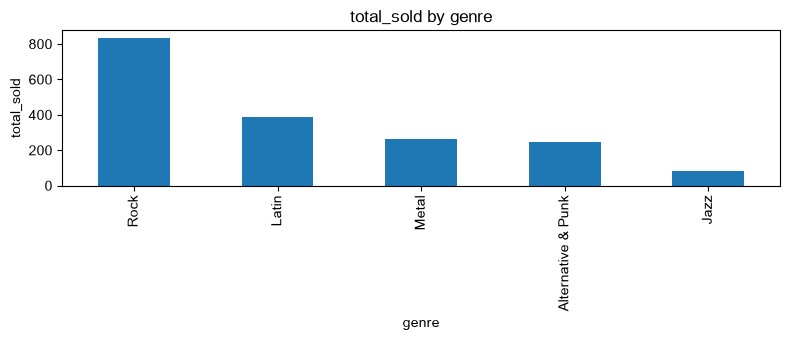

【第 4 轮】用户：每个流派有多少艺人/歌手？


[A] 追问改写为独立问题：数据库中每个流派分别有多少个不同的艺人/歌手？


[B] 范围判定：in（可通过 tracks 关联 albums 和 artists，再按 genres 分组统计不同 ArtistId 数量）


[2] 选中表：['genres', 'tracks', 'albums']


[3] 生成 SQL：SELECT genres.GenreId, genres.Name, COUNT(DISTINCT albums.ArtistId) AS ArtistCount
FROM genres
LEFT JOIN tracks ON genres.GenreId = tracks.GenreId
LEFT JOIN albums ON tracks.AlbumId = albums.AlbumId
GROUP BY genres.GenreId, genres.Name;
[4] 校验（第 1 次）：通过
[6] 执行结果：25 行


[7] 汇总回答：数据库中共有 25 个流派，各流派对应的不同艺人数如下：

| 流派 | 不同艺人数 |
|---|---:|
| Classical | 66 |
| Rock | 51 |
| Latin | 28 |
| Alternative & Punk | 16 |
| Metal | 14 |
| Jazz | 10 |
| Blues | 5 |
| TV Shows | 5 |
| Alternative | 5 |
| Soundtrack | 4 |
| R&B/Soul | 4 |
| Reggae | 3 |
| Pop | 3 |
| Electronica/Dance | 3 |
| World | 3 |
| Hip Hop/Rap | 2 |
| Sci Fi & Fantasy | 2 |
| Drama | 2 |
| Rock And Roll | 1 |
| Bossa Nova | 1 |
| Easy Listening | 1 |
| Heavy Metal | 1 |
| Science Fiction | 1 |
| Comedy | 1 |
| Opera | 1 |

结论：不同艺人数最多的是 **Classical（66 个）**，其次是 **Rock（51 个）** 和 **Latin（28 个）**；其余流派的不同艺人数相对较少，多数在 1 到 16 个之间。
助手： 数据库中共有 25 个流派，各流派对应的不同艺人数如下：

| 流派 | 不同艺人数 |
|---|---:|
| Classical | 66 |
| Rock | 51 |
| Latin | 28 |
| Alternative & Punk | 16 |
| Metal | 14 |
| Jazz | 10 |
| Blues | 5 |
| TV Shows | 5 |
| Alternative | 5 |
| Soundtrack | 4 |
| R&B/Soul | 4 |
| Reggae | 3 |
| Pop | 3 |
| Electronica/Dance | 3 |
| World | 3 |
| Hip Hop/Rap | 2 |
| Sci Fi & Fantasy | 2 |
| Drama | 2 |


,GenreId,Name,ArtistCount
0,1,Rock,51
1,2,Jazz,10
2,3,Metal,14
3,4,Alternative & Punk,16
4,5,Rock And Roll,1
5,6,Blues,5
6,7,Latin,28
7,8,Reggae,3
8,9,Pop,3
9,10,Soundtrack,4


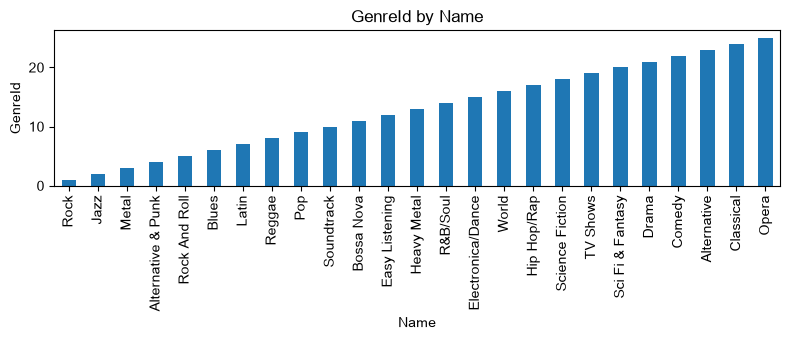

【第 5 轮】用户：每个流派歌曲最多的前三位歌手是谁？


[A] 追问改写为独立问题：在数据库中，请按每个流派分别统计歌曲数量最多的前三位艺人/歌手是谁？


[B] 范围判定：in（可使用 genres、tracks、albums、artists 关联后按流派和艺人统计歌曲数量并取每流派前三。）


[2] 选中表：['genres', 'tracks', 'albums', 'artists']


[3] 生成 SQL：WITH artist_genre_counts AS (
  SELECT
    g.GenreId,
    g.Name AS GenreName,
    ar.ArtistId,
    ar.Name AS ArtistName,
    COUNT(t.TrackId) AS TrackCount
  FROM genres g
  JOIN tracks t ON t.GenreId = g.GenreId
  JOIN albums al ON al.AlbumId = t.AlbumId
  JOIN artists ar ON ar.ArtistId = al.ArtistId
  GROUP BY g.GenreId, g.Name, ar.ArtistId, ar.Name
),
ranked AS (
  SELECT
    GenreId,
    GenreName,
    ArtistId,
    ArtistName,
    TrackCount,
    ROW_NUMBER() OVER (
      PARTITION BY GenreId
      ORDER BY TrackCount DESC, ArtistName ASC
    ) AS rn
  FROM artist_genre_counts
)
SELECT
  GenreId,
  GenreName,
  ArtistId,
  ArtistName,
  TrackCount
FROM ranked
WHERE rn <= 3
ORDER BY GenreId, rn;
[4] 校验（第 1 次）：通过
[6] 执行结果：58 行


[7] 汇总回答：根据查询结果（括号内为歌曲数），在**已展示的范围内**，各流派歌曲数量最多的前三位艺人/歌手如下：

- **Rock**：Led Zeppelin（114）、U2（112）、Deep Purple（92）
- **Jazz**：Miles Davis（37）、Gene Krupa（22）、Spyro Gyra（21）
- **Metal**：Metallica（112）、Iron Maiden（95）、Black Label Society（18）
- **Alternative & Punk**：Titãs（38）、Faith No More（37）、Green Day（34）
- **Rock And Roll**：BackBeat（12）
- **Blues**：Eric Clapton（32）、The Black Crowes（19）、Buddy Guy（11）
- **Latin**：Os Paralamas Do Sucesso（49）、Chico Science & Nação Zumbi（36）、Chico Buarque（34）
- **Reggae**：Cidade Negra（31）、UB40（14）、Lenny Kravitz（13）
- **Pop**：U2（23）、Various Artists（14）、Amy Winehouse（11）
- **Soundtrack**：Gilberto Gil（14）、Passengers（14）、Various Artists（14）
- **Bossa Nova**：Toquinho & Vinícius（15）
- **Easy Listening**：Frank Sinatra（24）
- **Heavy Metal**：Iron Maiden（28）
- **R&B/Soul**：James Brown（20）、Marvin Gaye（18）、Amy Winehouse（12）
- **Electronica/Dance**：O Rappa（17）、Jamiroquai（11）、Karsh Kale（2）
- **World**：João Suplicy（14）、Mônica Marianno（12）、Habib Koité and Bamada（2）
- **Hip 

... (9 outputs left out)

  [判定 out] 秦始皇统一六国是在哪一年？


  [判定 out] 如何提高睡眠质量？
② 缺主语样本（无上下文，期望 ambiguous）：


  [判定 ambiguous] 有多少？  → 澄清语：请问您想统计什么的数量？例如：专辑数量、艺术家数量、客户数量、曲目数量、发票数量等。


  [判定 ambiguous] 排行前十是谁？  → 澄清语：请问要统计哪一类排行前十？例如最畅销的艺术家、歌曲、专辑，或消费金额最高的客户，并按销量还是销售额排序？


In [17]:
bot = ChatBI(parser)

CHAT_TURNS = [
    "数据库里一共有多少首歌曲？",                    # in：单值统计
    "那其中有多少个不同的流派？",                    # in：追问（依赖上下文）
    "销量最高的 5 个流派分别是哪些，各卖了多少？",    # in：分组 → 表格 + 图
    '每个流派有多少艺人/歌手？',
    '每个流派歌曲最多的前三位歌手是谁？',
    "有多少？",                                     # 缺主语；被 [A] 结合上文补全 → in
    "帮我写一首关于夏天的诗",                        # out：与库无关
    "明天北京的天气怎么样？",                        # out：需要库外数据
]

# CHAT_TURNS = [input()]


for n, q in enumerate(CHAT_TURNS, 1):
    print("=" * 72)
    print(f"【第 {n} 轮】用户：{q}")
    res = bot.ask(q, show_trace=True)
    print("助手：", res["answer"])
    if res.get("rows"):
        render_result(res)


print("\n=== 范围守门人回归（直接调 scope_check，绕过上下文改写）===")

print("① 越界负样本（期望 out）：")
for q in simulate_out_of_scope(4):
    print(f"  [判定 {scope_check(q, parser)['scope']}] {q}")

print("② 缺主语样本（无上下文，期望 ambiguous）：")
for q in ["有多少？", "排行前十是谁？"]:
    r = scope_check(q, parser)
    print(f"  [判定 {r['scope']}] {q}  → 澄清语：{r['clarify']}")

In [18]:
# 真实交互入口：把 INTERACTIVE 改为 True 即可手动多轮对话（nbconvert 无头执行时跳过）
INTERACTIVE = False
if INTERACTIVE:
    _bot = ChatBI(parser)
    while True:
        q = input("你：").strip()
        if q in ("", "exit", "quit", "退出"):
            break
        _res = _bot.ask(q, show_trace=True)
        print("助手：", _res["answer"])
        render_result(_res)

### 交互输入框（ipywidgets）

比 `input()` 更适合「真·对接用户」：输入框**不阻塞内核**——`Run All` / `nbconvert` 也能正常跑完；
在 Jupyter 里直接敲问题、点「提问」即可。链路与多轮入口一致（走 `ChatBI` 的三道闸门：
追问改写 → 范围判定 → 分支）。

In [19]:
import ipywidgets as widgets
from IPython.display import clear_output, display, Markdown

_ui_bot = ChatBI(parser)

_q_box = widgets.Text(
    placeholder="输入你的问题，例如：销量最高的 5 个流派分别是哪些？",
    layout=widgets.Layout(width="72%"),
)
_ask_btn = widgets.Button(description="提问", button_style="primary")
_ui_out = widgets.Output()


def _on_ask(_btn):
    q = _q_box.value.strip()
    if not q:
        return
    with _ui_out:
        clear_output(wait=True)
        res = _ui_bot.ask(q, show_trace=True)
        display(Markdown(f"**助手：** {res['answer']}"))
        if res.get("rows"):
            render_result(res)
    _q_box.value = ""


_ask_btn.on_click(_on_ask)
display(widgets.HBox([_q_box, _ask_btn]), _ui_out)

Output()

## 10. 逐层裁判验证（JudgeAgent + 冻结验证集）

目标：在**大规模使用 SQL Agent 之前**，用「带答案的验证集」逐步校验它的取数逻辑是否严谨正确。

**为什么要「逐步」**：一次问答的错误可能注入在 5 个跳跃点；只看终点值既无法定位，
也会放过「结论对、过程错」（例如选错表却恰好数值撞对）：

```
问题 ─①→ 选表 ─②→ 生成 SQL ─③→ 校验 ─④→ 执行 ─⑤→ 汇总回答
```

**两条第一性原理**

1. **可判定 vs 需判断**：数值是否相等、SQL 能否执行、有无写操作、答案里的数字能否在结果里找到
   —— 这些**用代码断言就够，不劳 LLM**；只有「这条 SQL 是否忠实表达了问题」这类语义问题才需要裁判。
2. **LLM 裁判必须带参照物**：给它「问题 + 待审 SQL + 权威 SQL」「问题 + 权威结果 + 参考要点」，
   把「你觉得对吗」变成「对照批改（rubric + reference）」，否则会退化成两个模型对喷。

**验证集为什么要冻结**：`GOLDEN_SET` 一次编好、只读；`ref_rows` 由手写 `ref_sql`
经 **双引擎（SQLAlchemy + 原生 sqlite3）交叉验证**后固化。评测时只读、绝不重算 ——
既保证可复现，也让「答案」独立于「答题模型」，避免自证偏差。

**5 层裁判**

| 层 | 阶段 | 裁判函数 | 类型 | 判据 |
|---|---|---|---|---|
| L0 | 闸门 | `judge_scope` | 确定性 | scope 标签与权威一致 |
| L1 | 选表 | `judge_tables` (+LLM) | 确定 + LLM | 是否覆盖必需表；多余表交 LLM 判是否无害 |
| L2 | 生成 | `judge_sql` | LLM | 与权威 SQL 是否语义等价 |
| L3 | 校验 | `judge_guard` | 确定性 | 是否产出可执行 SQL（只读守卫放行） |
| L4 | 执行 | `judge_result` (+LLM) | 确定 + LLM | 结果集等价（行序无关 + 数值容差）；判不一致时交 LLM 做语义复核 |
| L5 | 汇总 | `judge_answer` (+数字溯源) | LLM + 确定性 | 要点覆盖 + 数字能否溯源 |

> 端到端通过 = 上述「有判定」的层全部通过。裁判返回 `None`（如 JSON 解析失败）表示
> 「未给出结论」，不计入通过性，但会在明细里显式暴露，不掩盖问题。

> **为什么 L4 还要 LLM 兜底**：结果集「严格相等」只是**充分不必要条件** —— Agent 可能把
> `FirstName`、`LastName` 拆成两列，语义没错但形状与权威单列不同。故确定性比较判不一致时，
> 升级到 LLM 做「口径是否一致」的语义复核，避免把「语义正确但形状不同」误杀。


In [20]:
"""10.1 冻结验证集：手写 ref_sql + 双引擎固化的 ref_rows（评测时只读）。

设计要点：
- ref_rows 由手写 ref_sql 经「SQLAlchemy + 原生 sqlite3」双引擎交叉验证后固化；
- 评测只读这个常量，绝不重算 —— 保证可复现，且答案独立于答题模型（避免自证偏差）。
"""

GOLDEN_SET = [
    {"id": "G1", "question": "数据库里一共有多少首歌曲？", "scope": "in",
     "tables": ["tracks"],
     "ref_sql": "SELECT COUNT(*) AS track_count FROM tracks;",
     "ref_rows": [(3503,)],
     "ref_answer_keypoints": ["3503"], "tags": ["count"]},

    {"id": "G2", "question": "数据库里一共有多少张专辑？", "scope": "in",
     "tables": ["albums"],
     "ref_sql": "SELECT COUNT(*) AS album_count FROM albums;",
     "ref_rows": [(347,)],
     "ref_answer_keypoints": ["347"], "tags": ["count"]},

    {"id": "G3", "question": "数据库里一共有多少位客户？", "scope": "in",
     "tables": ["customers"],
     "ref_sql": "SELECT COUNT(*) AS customer_count FROM customers;",
     "ref_rows": [(59,)],
     "ref_answer_keypoints": ["59"], "tags": ["count"]},

    {"id": "G4", "question": "数据库里一共有多少名员工？", "scope": "in",
     "tables": ["employees"],
     "ref_sql": "SELECT COUNT(*) AS employee_count FROM employees;",
     "ref_rows": [(8,)],
     "ref_answer_keypoints": ["8"], "tags": ["count"]},

    {"id": "G5", "question": "账单国家是德国的发票有多少张？", "scope": "in",
     "tables": ["invoices"],
     "ref_sql": "SELECT COUNT(*) AS invoice_count FROM invoices WHERE BillingCountry = 'Germany';",
     "ref_rows": [(28,)],
     "ref_answer_keypoints": ["28"], "tags": ["count", "filter"]},

    {"id": "G6", "question": "销量最高的 5 个流派分别是什么，各卖了多少？", "scope": "in",
     "tables": ["genres", "tracks", "invoice_items"],
     "ref_sql": ("SELECT g.Name AS genre, SUM(ii.Quantity) AS sold "
                 "FROM genres g JOIN tracks t ON t.GenreId = g.GenreId "
                 "JOIN invoice_items ii ON ii.TrackId = t.TrackId "
                 "GROUP BY g.GenreId, g.Name ORDER BY sold DESC LIMIT 5;"),
     "ref_rows": [("Rock", 835), ("Latin", 386), ("Metal", 264),
                  ("Alternative & Punk", 244), ("Jazz", 80)],
     "ref_answer_keypoints": ["Rock", "835", "Latin", "386"],
     "tags": ["join", "aggregate", "topk"]},

    {"id": "G7", "question": "每位客服各自负责多少位客户？", "scope": "in",
     "tables": ["employees", "customers"],
     "ref_sql": ("SELECT e.FirstName || ' ' || e.LastName AS support_rep, "
                 "COUNT(c.CustomerId) AS customers "
                 "FROM employees e JOIN customers c ON c.SupportRepId = e.EmployeeId "
                 "GROUP BY e.EmployeeId ORDER BY customers DESC;"),
     "ref_rows": [("Jane Peacock", 21), ("Margaret Park", 20), ("Steve Johnson", 18)],
     "ref_answer_keypoints": ["Jane Peacock", "21", "Steve Johnson", "18"],
     "tags": ["join", "group"]},

    {"id": "G8", "question": "哪个客户的累计消费金额最高？", "scope": "in",
     "tables": ["customers", "invoices"],
     "ref_sql": ("SELECT c.FirstName || ' ' || c.LastName AS customer, "
                 "SUM(i.Total) AS total_spent "
                 "FROM customers c JOIN invoices i ON i.CustomerId = c.CustomerId "
                 "GROUP BY c.CustomerId ORDER BY total_spent DESC LIMIT 1;"),
     "ref_rows": [("Helena Holý", 49.62)],
     "ref_answer_keypoints": ["Helena Holý", "49.62"], "tags": ["join", "topk"]},

    {"id": "G9", "question": "2010 年的总销售额是多少？", "scope": "in",
     "tables": ["invoices"],
     "ref_sql": ("SELECT SUM(Total) AS total_sales FROM invoices "
                 "WHERE InvoiceDate >= '2010-01-01' AND InvoiceDate < '2011-01-01';"),
     "ref_rows": [(481.45,)],
     "ref_answer_keypoints": ["481.45"], "tags": ["filter", "aggregate"]},

    # ---- 闸门样本：不进入流水线，只校验 [B] 范围判定 ----
    {"id": "N1", "question": "明天北京的天气怎么样？", "scope": "out",
     "tables": [], "ref_sql": None, "ref_rows": None,
     "ref_answer_keypoints": [], "tags": ["gate"]},
    {"id": "N2", "question": "帮我写一首关于夏天的诗", "scope": "out",
     "tables": [], "ref_sql": None, "ref_rows": None,
     "ref_answer_keypoints": [], "tags": ["gate"]},
    {"id": "N3", "question": "有多少？", "scope": "ambiguous",
     "tables": [], "ref_sql": None, "ref_rows": None,
     "ref_answer_keypoints": [], "tags": ["gate"]},
]


def freeze_golden(golden=None, parser=None):
    """重建并固化 ref_rows：双引擎交叉验证，不一致立即报错。

    只在需要重建验证集时手动调用；日常评测只读 GOLDEN_SET 里已冻结的值。
    """
    import sqlite3

    golden = golden if golden is not None else GOLDEN_SET
    con = sqlite3.connect(str(_db_path))
    try:
        for it in golden:
            if it["scope"] != "in":
                continue
            _, rows_a = parser.execute_sql(it["ref_sql"])       # 引擎 A：SQLAlchemy
            rows_b = con.execute(it["ref_sql"]).fetchall()      # 引擎 B：原生 sqlite3
            if sorted(map(str, rows_a)) != sorted(map(str, rows_b)):
                raise AssertionError(f"{it['id']} 双引擎结果不一致：{rows_a} vs {rows_b}")
            it["ref_rows"] = rows_a
    finally:
        con.close()
    return golden


_scope_count = {s: sum(x["scope"] == s for x in GOLDEN_SET) for s in ("in", "out", "ambiguous")}
print(f"验证集共 {len(GOLDEN_SET)} 题：in {_scope_count['in']} / "
      f"out {_scope_count['out']} / ambiguous {_scope_count['ambiguous']}；ref_rows 已冻结")


验证集共 12 题：in 9 / out 2 / ambiguous 1；ref_rows 已冻结


In [21]:
"""10.2 确定性裁判：只用代码断言，不调用 LLM。

凡是「可判定」的（结果集相等、能否执行、闸门标签）都在这一层用硬规则判死；
只有「语义」问题才留给 10.3 的 LLM 裁判。

注意 L4：结果集「严格相等」是**充分不必要条件** —— Agent 可能把姓名拆成
FirstName / LastName 两列，语义没错但形状不同。故这里只给确定性判据；一旦判 FAIL，
由 10.4 升级到 10.3 的 judge_result_llm 做语义复核。
"""


def _norm_cell(v):
    """单元格归一：数值四舍五入到 1e-6，其余转字符串。"""
    if isinstance(v, bool):
        return str(v)
    if isinstance(v, (int, float)):
        return round(float(v), 6)
    return None if v is None else str(v).strip()


def normalize_rows(rows):
    """结果集归一：数值容差 + 行序无关（排序后比较）。"""
    if rows is None:
        return None
    return sorted(tuple(_norm_cell(c) for c in r) for r in rows)


def row_equal(a, b):
    return normalize_rows(a) == normalize_rows(b)


def judge_scope(item, trace):
    """L0：闸门判定是否与权威标签一致。"""
    got = (trace.get("scope") or {}).get("scope")
    ok = got == item["scope"]
    return {"pass": ok, "detail": "" if ok else f"闸门判定 {got}，期望 {item['scope']}"}


def judge_tables(item, trace):
    """L1（确定性部分）：选中表是否覆盖权威所需的表。"""
    if item["scope"] != "in":
        return {"pass": True, "detail": "闸门样本，跳过"}
    want, got = set(item["tables"]), set(trace.get("tables") or [])
    missing, extra = want - got, got - want
    msgs = []
    if missing:
        msgs.append(f"缺表 {sorted(missing)}")
    if extra:
        msgs.append(f"多选 {sorted(extra)}")
    return {"pass": not missing, "want": sorted(want), "got": sorted(got),
            "detail": "；".join(msgs) or "集合一致"}


def judge_guard(item, trace):
    """L3：只读守卫 + 校验是否按预期放行（是否产出了可执行 SQL）。"""
    if item["scope"] != "in":
        return {"pass": True, "detail": "闸门样本，跳过"}
    ok = bool(trace.get("ok"))
    return {"pass": ok,
            "detail": "可执行" if ok else f"未能产出可执行 SQL：{str(trace.get('error'))[:120]}"}


def judge_result(item, trace):
    """L4（确定性部分）：结果集严格等价 —— 数值 / 表格题的硬判据。

    判 FAIL 不等价于「结果错」，只表示「形状/内容与权威不一致」，可能语义正确；
    由 JudgeAgent 升级到 LLM 复核。
    """
    if item["scope"] != "in":
        return {"pass": True, "detail": "闸门样本，跳过"}
    if not trace.get("ok"):
        return {"pass": False, "detail": "执行失败，无结果可判"}
    got, want = trace.get("rows"), item["ref_rows"]
    ok = row_equal(got, want)
    return {"pass": ok, "got": got, "want": want,
            "detail": "结果集严格一致" if ok else f"形状/内容不一致：got={got!r}，want={want!r}"}


_NUM_RE = re.compile(r"-?\d+(?:\.\d+)?")


def _nums(text):
    return [m.group(0) for m in _NUM_RE.finditer(text or "")]


def _fmt(v):
    try:
        return f"{float(v):g}"
    except (TypeError, ValueError):
        return None


def judge_number_trace(item, trace):
    """L5 诊断（确定性）：答案里的数字能否在「结果集 / 派生合计 / 问题」里找到来源。

    这是**诊断信号**，不参与 pass/fail —— 命中只代表「疑似编造」，需人工/LLM 复核。
    为抑制误报，除「结果集数字 + 问题数字」外再做两类豁免：
    1. **派生合计豁免**：把每个数值列的总和也放进来源池（如客服客户数 21+20+18=59）；
    2. **名次/编号豁免**：整数值落在 [1, 结果行数] 内，视为列表序号（如「1. Rock 2. Latin」）。
    """
    if item["scope"] != "in" or not trace.get("rows"):
        return {"suspicious": []}
    rows = trace["rows"]
    ncol = len(rows[0]) if rows else 0

    pool = set()
    for r in rows:
        for c in r:
            if isinstance(c, (int, float)) and not isinstance(c, bool):
                pool.add(f"{float(c):g}")
            else:
                pool.update(n for n in map(_fmt, _nums(str(c))) if n)
    # 派生合计豁免：数值列整列求和
    for j in range(ncol):
        col = [r[j] for r in rows
               if isinstance(r[j], (int, float)) and not isinstance(r[j], bool)]
        if col:
            pool.add(f"{float(sum(col)):g}")

    q_num = {n for n in map(_fmt, _nums(item["question"])) if n}
    rank_exempt = set(range(1, len(rows) + 1))  # 名次/编号豁免

    suspicious = []
    for tok in _nums(trace.get("answer") or ""):
        val = float(tok)
        if f"{val:g}" in pool or f"{val:g}" in q_num:
            continue
        if val.is_integer() and int(val) in rank_exempt:
            continue
        suspicious.append(tok)
    return {"suspicious": suspicious}


In [22]:
"""10.3 LLM 裁判：只在「语义不可判定」处使用，且必须带参照物（rubric + reference）。

三条规矩：
1. 能给参照物就给（问题 / 权威 SQL / 权威结果集）—— 把「你觉得对吗」变成「对照批改」；
2. 只输出 JSON，解析失败记 None（不计入 pass/fail），不猜；
3. 裁判只读 trace，不改动流水线。
"""

_JUDGE_SQL_SYS = (
    "你是严格的 SQL 语义审校员。请判断两条 SQL 在给定问题上是否语义等价："
    "忽略别名、写法、列顺序差异，只比较过滤条件 / 连接关系 / 聚合口径 / 排序与取值。"
    "只输出 JSON。"
)
_JUDGE_SQL_USER = """用户问题：{q}

待审 SQL：
{sql}

权威参考 SQL：
{ref}

请只输出 JSON：
{{"equivalent": true, "differences": ["若不等价，列出关键口径差异"], "score": 1.0}}"""


def judge_sql(item, trace):
    """L2：生成的 SQL 与权威 SQL 是否语义等价（LLM）。"""
    if item["scope"] != "in" or not trace.get("sql") or not item["ref_sql"]:
        return {"pass": True, "detail": "闸门样本，跳过", "score": None}
    raw = strip_code_fence(chat(_JUDGE_SQL_SYS, _JUDGE_SQL_USER.format(
        q=item["question"], sql=trace["sql"], ref=item["ref_sql"]), json_mode=True))
    try:
        d = json.loads(raw)
    except json.JSONDecodeError:
        return {"pass": None, "detail": f"裁判输出无法解析：{raw[:120]}", "score": None}
    eq = bool(d.get("equivalent"))
    diffs = d.get("differences") or []
    return {"pass": eq, "score": d.get("score"),
            "detail": "语义等价" if eq else ("；".join(map(str, diffs)) or "语义不等价")}


_JUDGE_TBL_SYS = "你是严格的选表审校员。判断「多选的表」是否会使结果口径改变或出错。只输出 JSON。"
_JUDGE_TBL_USER = """用户问题：{q}
权威所需表：{want}
实际多选的表：{extra}
本次选中的全部表：{got}

多选这些表是否会导致结果口径改变 / 出错？请只输出 JSON：
{{"harmless": true, "reason": "简短理由"}}"""


def judge_tables_llm(item, trace):
    """L1 增强：确定性命中但有「多余表」时，交 LLM 判是否无害。"""
    raw = strip_code_fence(chat(_JUDGE_TBL_SYS, _JUDGE_TBL_USER.format(
        q=item["question"], want=item["tables"],
        extra=sorted(set(trace.get("tables") or []) - set(item["tables"])),
        got=sorted(trace.get("tables") or [])), json_mode=True))
    try:
        d = json.loads(raw)
    except json.JSONDecodeError:
        return {"harmless": None, "reason": f"裁判输出无法解析：{raw[:80]}"}
    return {"harmless": d.get("harmless"), "reason": d.get("reason", "")}


_JUDGE_RES_SYS = (
    "你是严格的结果集审校员。请判断「助手结果」与「权威结果」在回答同一个问题时是否语义一致。"
    "以下都**不算**差异：列被拆分或合并（如把 FirstName、LastName 合写成全名）、别名不同、"
    "行序不同、列顺序不同、数值格式不同。只有过滤口径、聚合口径、取值口径不一致才算差异。"
    "只输出 JSON。"
)
_JUDGE_RES_USER = """用户问题：{q}

权威结果（参考答案）：{want}

助手结果：{got}

请判断两者在回答该问题上是否语义一致。只输出 JSON：
{{"equivalent": true, "differences": ["若不一致，列出关键口径差异"], "reason": "简短理由"}}"""


def judge_result_llm(item, trace):
    """L4 增强：确定性结果集比较判 FAIL 时，交 LLM 做「语义等价」复核。

    只在形状/列数不一致等无法用代码判死的情形触发，避免把「语义正确但形状不同」
    误判为错（结果集严格相等只是充分不必要条件）。
    """
    raw = strip_code_fence(chat(_JUDGE_RES_SYS, _JUDGE_RES_USER.format(
        q=item["question"], want=item["ref_rows"], got=trace.get("rows")), json_mode=True))
    try:
        d = json.loads(raw)
    except json.JSONDecodeError:
        return {"equivalent": None, "reason": f"裁判输出无法解析：{raw[:80]}", "differences": []}
    return {"equivalent": d.get("equivalent"), "reason": d.get("reason", ""),
            "differences": d.get("differences") or []}


_JUDGE_ANS_SYS = (
    "你是严格的结果校对员。请判断「助手回答」是否忠实覆盖了「参考要点」，"
    "且没有编造与权威执行结果冲突的数字。只输出 JSON。"
)
_JUDGE_ANS_USER = """用户问题：{q}

权威执行结果：{rows}

参考要点：{kp}

助手回答：
{ans}

请只输出 JSON：
{{"covered": ["已覆盖的要点"], "missing": ["遗漏的要点"],
  "faithful": true, "reason": "简短理由", "score": 1.0}}"""


def judge_answer(item, trace):
    """L5：汇总回答是否忠实、要点是否齐全（LLM）。"""
    if item["scope"] != "in" or not trace.get("answer"):
        return {"pass": True, "detail": "闸门样本，跳过", "score": None}
    raw = strip_code_fence(chat(_JUDGE_ANS_SYS, _JUDGE_ANS_USER.format(
        q=item["question"], rows=(trace.get("rows") or [])[:50],
        kp=item.get("ref_answer_keypoints") or [], ans=trace["answer"]), json_mode=True))
    try:
        d = json.loads(raw)
    except json.JSONDecodeError:
        return {"pass": None, "detail": f"裁判输出无法解析：{raw[:120]}", "score": None}
    missing = d.get("missing") or []
    ok = bool(d.get("faithful")) and not missing
    return {"pass": ok, "score": d.get("score"),
            "detail": "忠实且要点齐全" if ok else f"遗漏 {missing}；{d.get('reason', '')}"}


In [23]:
"""10.4 编排：JudgeAgent 把 5 层裁判断一遍，给出逐层结论与端到端判定。

判定语义：pass 为 True/False 表示「有判定」；None 表示「裁判未给出结论」
（如 JSON 解析失败 / LLM 关闭），不计入端到端通过性，但会在明细里显式暴露。

两处「确定性 → LLM」升级：
- L1：确定性命中但选多了表 → 交 LLM 判多余表是否无害；
- L4：确定性结果集不一致（多为形状/列数不同）→ 交 LLM 做语义等价复核。
"""


class JudgeAgent:
    """逐层裁判：对同一道题的 trace 依次跑 L0..L5，最后聚合端到端结论。"""

    def __init__(self, use_llm: bool = True):
        self.use_llm = use_llm

    def judge(self, item, trace) -> dict:
        layers = {
            "L0_scope": judge_scope(item, trace),
            "L1_tables": judge_tables(item, trace),
            "L2_sql": judge_sql(item, trace) if self.use_llm
                      else {"pass": None, "detail": "LLM 关闭", "score": None},
            "L3_guard": judge_guard(item, trace),
            "L4_result": judge_result(item, trace),
            "L5_answer": judge_answer(item, trace) if self.use_llm
                         else {"pass": None, "detail": "LLM 关闭", "score": None},
        }

        # L1 增强：确定性命中但有「多余表」→ 交 LLM 判是否无害
        extra = set(trace.get("tables") or []) - set(item["tables"])
        if self.use_llm and extra and layers["L1_tables"].get("pass") is True:
            human = judge_tables_llm(item, trace)
            layers["L1_tables"]["detail"] += f"；多余表 {sorted(extra)}：{human.get('reason', '')}"
            if human.get("harmless") is False:
                layers["L1_tables"]["pass"] = False

        # L4 增强：确定性判不一致 → 交 LLM 做「语义等价」复核（形状不同 ≠ 结果错）
        if self.use_llm and layers["L4_result"].get("pass") is False:
            human = judge_result_llm(item, trace)
            if human.get("equivalent") is True:
                layers["L4_result"]["pass"] = True
                layers["L4_result"]["detail"] = (
                    f"严格比较不一致，但 LLM 复核语义等价：{human.get('reason', '')}")
            elif human.get("equivalent") is False:
                layers["L4_result"]["detail"] += (
                    f"；LLM 复核仍不等价：{human.get('reason', '')}")

        # L5 诊断：数字溯源（不参与 pass/fail）
        layers["L5_answer"]["suspicious"] = judge_number_trace(item, trace)["suspicious"]

        judged = [v["pass"] for v in layers.values() if v.get("pass") is not None]
        return {"id": item["id"], "question": item["question"], "scope": item["scope"],
                "layers": layers, "pass": all(judged)}


In [24]:
"""10.5 跑全量：对每题先跑 Agent 链路，再逐层裁判，产出明细与汇总指标。"""

RUN_JUDGE_EVAL = True  # 置 False 可跳过（本 demo 题量小，默认随 Run All 执行）


def run_and_judge(item, judge, parser):
    """统一走 ChatBI.ask 入口 —— 它的 trace 一定含 `scope`（闸门结论），
    in 题还会带上完整流水线结果；out / ambiguous 题则停在闸门、不生成 SQL。

    每题用一个独立的 ChatBI 实例，避免对话历史在题目之间串味。
    """
    bot = ChatBI(parser)
    trace = bot.ask(item["question"])
    return judge.judge(item, trace)


if RUN_JUDGE_EVAL:
    judge = JudgeAgent(use_llm=True)
    _rows = []
    for it in tqdm(GOLDEN_SET):
        rep = run_and_judge(it, judge, parser)
        row = {"id": rep["id"], "question": rep["question"], "scope": rep["scope"]}
        for name, r in rep["layers"].items():
            row[name] = {True: "PASS", False: "FAIL", None: "—"}[r.get("pass")]
        row["suspicious"] = ", ".join(rep["layers"]["L5_answer"].get("suspicious") or [])
        row["pass"] = rep["pass"]
        _rows.append(row)

    judge_df = pd.DataFrame(_rows)
    _layer_cols = [c for c in judge_df.columns if c.startswith("L")]

    print("=== 逐题逐层明细 ===")
    display(judge_df)

    print("\n=== 汇总指标 ===")
    for c in _layer_cols:
        judged = judge_df[judge_df[c] != "—"]
        rate = (judged[c] == "PASS").mean() if len(judged) else float("nan")
        print(f"{c:10s} 通过率 {rate:7.1%}  （判定 {len(judged)} 题）")
    print(f"{'端到端':10s} 通过率 {judge_df['pass'].mean():7.1%}  "
          f"（{int(judge_df['pass'].sum())}/{len(judge_df)}）")
    _sus = sum(len([x for x in str(s).split(",") if x.strip()]) for s in judge_df["suspicious"])
    print(f"{'可疑数字':10s} {_sus} 个（诊断信号，不参与通过性判定）")

    print("\n=== 失败定位（端到端未通过的题）===")
    _bad = judge_df[~judge_df["pass"]]
    if not len(_bad):
        print("- 无：全部题目端到端通过")
    for _, r in _bad.iterrows():
        fails = [c for c in _layer_cols if r[c] == "FAIL"]
        print(f"- [{r['id']}] {r['question']}  失败层：{fails or '无（裁判未给出结论）'}")


  0%|          | 0/12 [00:00<?, ?it/s]

=== 逐题逐层明细 ===


,id,question,scope,L0_scope,L1_tables,L2_sql,L3_guard,L4_result,L5_answer,suspicious,pass
0,G1,数据库里一共有多少首歌曲？,in,PASS,PASS,PASS,PASS,PASS,PASS,,True
1,G2,数据库里一共有多少张专辑？,in,PASS,PASS,PASS,PASS,PASS,PASS,,True
2,G3,数据库里一共有多少位客户？,in,PASS,PASS,PASS,PASS,PASS,PASS,,True
3,G4,数据库里一共有多少名员工？,in,PASS,PASS,PASS,PASS,PASS,PASS,,True
4,G5,账单国家是德国的发票有多少张？,in,PASS,PASS,PASS,PASS,PASS,PASS,,True
5,G6,销量最高的 5 个流派分别是什么，各卖了多少？,in,PASS,PASS,PASS,PASS,PASS,PASS,,True
6,G7,每位客服各自负责多少位客户？,in,PASS,PASS,FAIL,PASS,PASS,PASS,,False
7,G8,哪个客户的累计消费金额最高？,in,PASS,PASS,PASS,PASS,PASS,PASS,,True
8,G9,2010 年的总销售额是多少？,in,PASS,PASS,PASS,PASS,PASS,PASS,,True
9,N1,明天北京的天气怎么样？,out,PASS,PASS,PASS,PASS,PASS,PASS,,True



=== 汇总指标 ===
L0_scope   通过率  100.0%  （判定 12 题）
L1_tables  通过率  100.0%  （判定 12 题）
L2_sql     通过率   91.7%  （判定 12 题）
L3_guard   通过率  100.0%  （判定 12 题）
L4_result  通过率  100.0%  （判定 12 题）
L5_answer  通过率  100.0%  （判定 12 题）
端到端        通过率   91.7%  （11/12）
可疑数字       0 个（诊断信号，不参与通过性判定）

=== 失败定位（端到端未通过的题）===
- [G7] 每位客服各自负责多少位客户？  失败层：['L2_sql']


**这一节给出了什么**：一套「冻结验证集 + 5 层裁判」的评测装置。
它把「SQL Agent 靠不靠谱」从一句感觉，变成一张可定位的表——
哪一题、哪一步、错在哪，都写清楚了，可作为规模化使用前的准入检查。

**已知限制**

1. **验证集规模小**（12 题，覆盖 count / join / topk / 闸门三类），要作为硬门槛还需扩样；
   扩充只需往 `GOLDEN_SET` 加「问题 + 手写 ref_sql」，再跑一次 `freeze_golden()` 即可。
2. **L2 / L5 是 LLM 裁判**，本身也具概率性：已用「带参照物 + 只输出 JSON + 解析失败记 None」
   约束，但不保证 100% 判准。
3. **L4 的严格比较会被 LLM 复核旁路**：结果是「语义等价」而非「字节相等」，
   当 Agent 输出形状与权威不同（如姓名拆列）时会被判过 —— 这是有意为之，但也意味着
   L4 不再是纯确定性判据，需要信任 LLM 复核的口径判断。
4. **数字溯源是诊断信号而非硬判据**：像「前 5 名」「2.2 倍」这类来自问题或派生计算的数字本就合法，
   已做「派生合计豁免 + 名次/编号豁免」抑制误报，但仍可能有残余噪音，不参与通过性。
5. **`ref_sql` 由人编写**：它定义了「权威口径」；若口径本身有争议，裁判结论也随之有争议 ——
   这是验证集的天花板，故务必人工确认后再冻结。
6. **未通过 ≠ 一定错**：L2 的 FAIL 可能只是「口径分歧」——例如 Agent 用 `LEFT JOIN` + `Title`
   过滤，权威用 `INNER JOIN`，结果恰好相同。本装置的价值是**定位到具体一跳并给出可读理由**，
   至于谁的口径更对，仍需人工判定，不能盲信裁判。


## 11. 结论与已知限制

**这条流水线做了什么**：把「解析 → 选表 → 生成 → 校验 → 改写 → 执行 → 汇总」拆成
7 个可独立观测的阶段，用 Python 编排，用只读守卫 + 校验闭环兜住 LLM 生成 SQL 的不确定性；再包一层 `ChatBI` 完成「多轮对话 + 表格/图表」的完整 ChatBI 闭环。

**已知限制**

1. LLM 生成 SQL 属概率性，同一问题两次可能得到不同 SQL；靠只读 + 校验闭环兜底，但不保证 100% 正确。
2. 评测集由 LLM 合成，存在自证偏差（同类模型造题 + 答题），指标仅供判断流程是否走得通。
3. Table 选择为单轮判断，跨多表复杂 join 可能漏表；已在表摘要中喂入外键关系缓解。
4. `check_sql` 采用「真跑一次」的方式校验；配合只读守卫，写入类语句在执行前已被拦下。
5. 未做多轮追问 / 澄清：问题模糊时不会反问，直接按最可能的意图生成。
- **范围判定**与**追问改写**同属 LLM 概率性判断；本实现用「结构兜底」（`tables` 必须落库）降低误判，但不保证 100% 准确。
- `scope_check()` 与 `select_tables()` 有一次重复的选表调用（都基于同一 catalog）；可合并以省一次 LLM 调用（已知优化点）。
